<a href="https://colab.research.google.com/github/charlottemarieolexy-tech/A04-clustering/blob/main/A04_Phase_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Charlotte Olexy

**Date:** 10/14/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


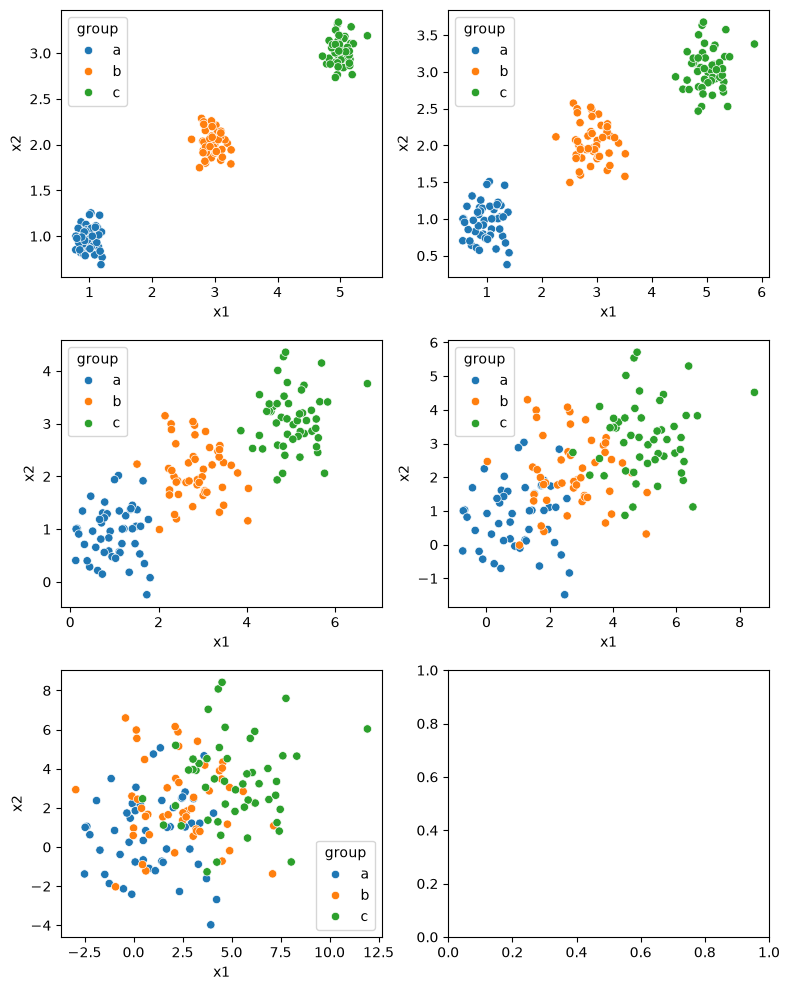

In [ ]:
#Making the Scatter plots
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

sns.scatterplot(
    data=df0_125,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[0,0]
)
sns.scatterplot(
    data=df0_25,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[0,1]
)
sns.scatterplot(
    data=df0_5,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[1,0],
)
sns.scatterplot(
    data=df1_0,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[1,1]
)
sns.scatterplot(
    data=df2_0,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[2,0]
)
plt.tight_layout()
plt.show()


As the noise increases from 0.125 to 2.0, the clusters become less defined, spread aapart, and overlap with the other clusters.

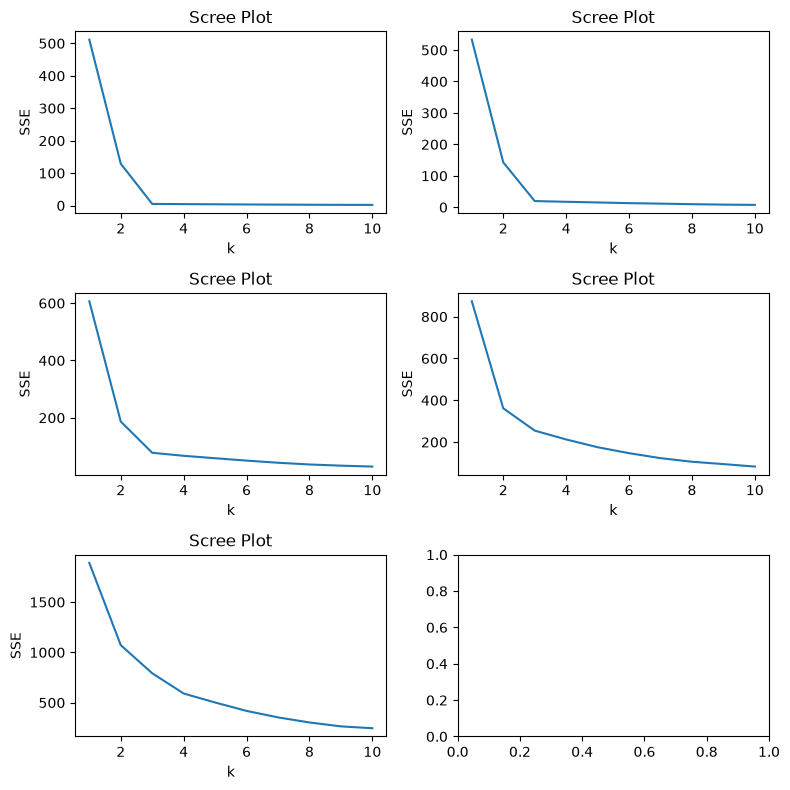

In [ ]:
#Scree Plot
from sklearn.cluster import KMeans

fig, axes = plt.subplots(3, 2, figsize=(8,8))


features= ["x1","x2"]

X = df0_125.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[0,0]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X1 = df0_25.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X1).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[0,1]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X2 = df0_5.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X2).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[1,0]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X3 = df1_0.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[1,1]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X4 = df2_0.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[2,0]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

plt.tight_layout()
plt.show()



As the datasets' noise increases, their respective Scree Plots smoothen out -- that is to say the defined elbow kink becomes less defined/sharp and a clear elbow becomes harder to see. This makes finding the ideal k much harder because the smoother plots have multiple points where it kinks that defines the curve.

Additionally, the starting SSE is increases with each plot (500 to 2000), which makes sense because SSE increases a lot when data is noiser.

#Explain the intuition of the elbow

The scree plot evaluates the SSE of the clusters evaluated at different values of k. It is often characterized by a noticeable kink in its curve, known as the elbow. An obvious elbow in the scree plot, like in df0_125, tells us what the optimal k value is (ie what the optimal number of clusters in). It tells us the optimal k because before the kink, k is allowing the SSE to have meaningful margins (decreasing by a lot rapidly). However after the kink, the SSE is decreasing at a less meaningful rate like diminishing marginal returns. Thus, adding more ks does not notably minimize our SSE by much more.

When the elbow is clear, we are able to find k* easily. However, when data is noisy, like in our example above with data set df2_0, the scree plot is more curved and visually "kinks" at many different points, making it harder to pinpoint the optimal k.

In [ ]:
#Question 2

military = pd.read_csv("SIPRI Military Expenditure Database.csv")

military.head()


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [ ]:
#copying dataset, dropping NaN values, and filtering it to only Year 2020
military_copy = military.copy().dropna()

military_copy = military_copy.query(
    'Year == 2020'
)

military_copy.head(145) #to see the US data and cross check with cluster data


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5336,5336,2020,Turkey,17478.413685,0.024322,0.071553,207.239992
5404,5404,2020,Uganda,984.759732,0.025971,0.121301,21.529038
5438,5438,2020,Ukraine,5924.200880,0.038118,0.082884,135.459845
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388


[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

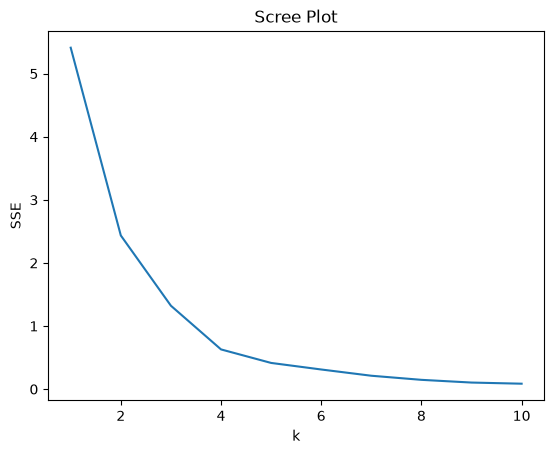

In [ ]:
#max-min normalizign spending 2020 and spending per capita

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Y = (unscaled - mins) / ranges
Y.agg(["min", "max"])

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(Y).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

<Axes: xlabel='Spending (2020 USD)', ylabel='Spending per Capita'>

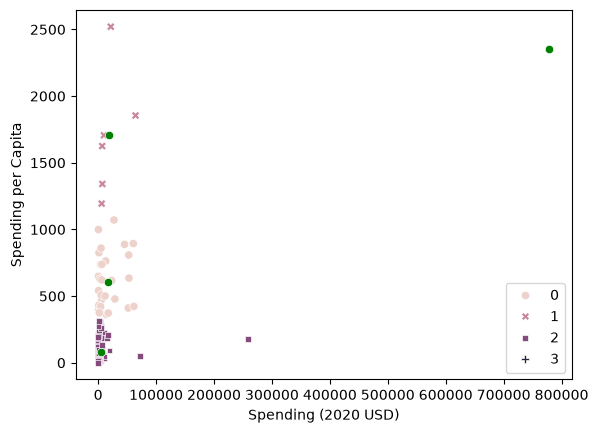

In [ ]:
#Scatter plot of Spending 2020 and Spending per Capita

model = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(Y)
military_copy["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=military_copy, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)

In [ ]:
#Describe Table
pd.set_option("display.max_columns", None)
military_copy.groupby("cluster").describe()

index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
1          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   
2        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
3          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year                                                       \
            max  count    mean  std     min     25%     50%     75%     max   
cluster                                                                       
0        5506.0   30.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        4656.0    6.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2        5880.0  111.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        5540.0    1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Percent of GDP                                                    \
                 count      mean       std       min       25%       50%   
cluster                                                                    
0                 30.0  0.019397  0.009272  0.006273  0.013892  0.018834   
1                  6.0  0.059781  0.031979  0.020060  0.035460  0.059257   
2                111.0  0.017349  0.011699  0.000054  0.010087  0.014389   
3                  1.0  0.037179       NaN  0.037179  0.037179  0.037179   

                            Percent of Government Spending            \
              75%       max                          count      mean   
cluster                                                                
0        0.022515  0.042634                           30.0  0.045588   
1        0.085398  0.098470                            6.0  0.127556   
2        0.021697  0.066600                          111.0  0.062059   
3        0.037179  0.037179                            1.0  0.081976   

                                                                     \
              std       min       25%       50%       75%       max   
cluster                                                               
0        0.030309  0.011613  0.026220  0.036053  0.048819  0.114776   
1        0.066569  0.035207  0.101034  0.113271  0.164503  0.225050   
2        0.045809  0.004896  0.032496  0.048698  0.083508  0.303027   
3             NaN  0.081976  0.081976  0.081976  0.081976  0.081976   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                

#What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

I noticed a few things from the scatterplot and describe table. The United States is the oly data point that makes up cluster 3 becuase its Spending (2020 USD) value is astronomically larger than any of the other countries. This is why there is no standard deviation becuase it is only one point. Cluster 3's central point covers the US's point on the scatterplot and it is visibly on the opposite end of the graph in relation to all of the other points/clusters.

Additionally, the other clusters are located in around 2020 Spending values close to 0. Cluster 2 holds most of the points because they consist of the countries that didn't spend that much in 2020 and had a low spending per capita. Cluster 0 and 1 are the upper two clusters of what appear as a vertically oriented group of points near the y axis. The cluster membership patterns makes sense intuitively as countries that spend less in 2020 means their spending per capita was also low. As the 2020 spending increased, so did the spending per capita, but the number of countries in these clusters decreased.

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

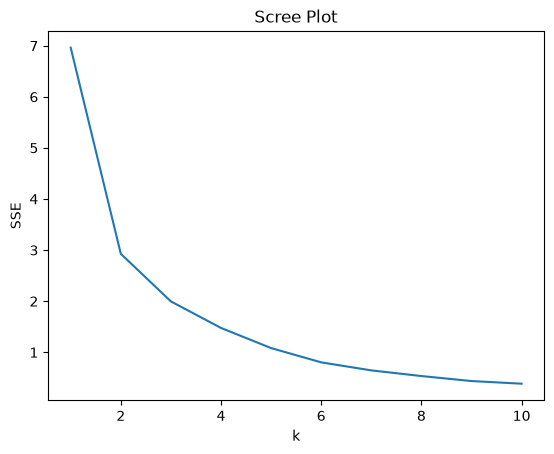

In [ ]:
#max-min normalizing % of government spending and percent of gdp

features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Z = (unscaled - mins) / ranges
Z.agg(["min", "max"])

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(Z).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

<Axes: xlabel='Percent of Government Spending', ylabel='Percent of GDP'>

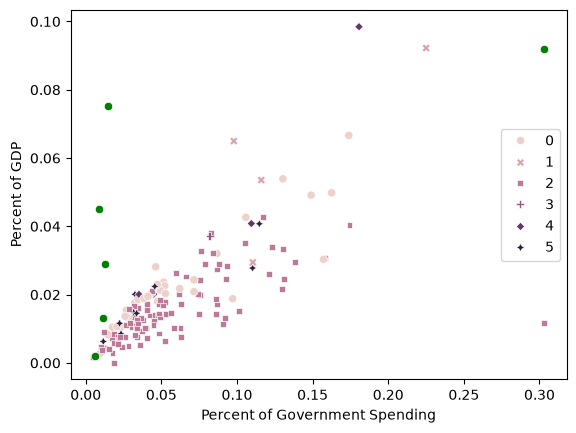

In [ ]:
#Scatter plot of Percent of Government Spending and Percent of GDP

model = KMeans(n_clusters=6, n_init="auto", random_state=0).fit(Y)
military_copy["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=military_copy, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)

In [ ]:
military_copy.groupby("cluster").describe()

index                                                            \
        count         mean          std     min     25%     50%     75%   
cluster                                                                   
0        31.0  2631.354839  1748.447341   100.0  1154.0  2616.0  4350.0   
1         4.0  3661.500000  1061.604289  2582.0  2837.0  3704.0  4528.5   
2        95.0  2849.705263  1626.105986    32.0  1545.0  2956.0  4112.0   
3         1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   
4         4.0  2242.000000  2069.070645   236.0   567.5  2344.0  4018.5   
5        13.0  2890.615385  1658.376593   338.0  1834.0  2854.0  3840.0   

                 Year                                                       \
            max count    mean  std     min     25%     50%     75%     max   
cluster                                                                      
0        5574.0  31.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        4656.0   4.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2        5880.0  95.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        5540.0   1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   
4        4044.0   4.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
5        5506.0  13.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      31.0   16844.488033  47017.556230     483.415023   
1                       4.0   25823.645885  26608.626022    6941.042345   
2                      95.0    2386.131634   8016.263370       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   
4                       4.0   10275.757917  11735.607400     436.548223   
5                      13.0   21161.400440  23080.230883     405.790494   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          1117.977870    3252.505062   10815.977520  257973.429834   
1          9219.189158   15897.570598   32502.027326   64558.400000   
2            86.622424     322.866526    1139.292075   72937.064048   
3        778397.200000  778397.200000  778397.200000  778397.200000   
4          4680.918590    6682.794371   12277.633697   27300.894701   
5          4087.541320    6389.669862   45523.984708   60675.039625   

        Percent of GDP                                                    \
                 count      mean       std       min       25%       50%   
cluster                                                                    
0                 31.0  0.024100  0.014429  0.002875  0.016526  0.020535   
1                  4.0  0.060038  0.026066  0.029429  0.047522  0.059257   
2                 95.0  0.015533  0.009322  0.000054  0.008873  0.013589   
3                  1.0  0.037179       NaN  0.037179  0.037179  0.037179   
4                  4.0  0.044864  0.037048  0.020060  0.020103  0.030463   
5                 13.0  0.017232  0.009017  0.006273  0.013862  0.014517   

                            Percent of Government Spending            \
              75%       max                          count      mean   
cluster                                                                
0        0.026227  0.066600                           31.0  0.063595   
1        0.071773  0.092211                            4.0  0.137368   
2        0.019947  0.042810                           95.0  0.058925   
3        0.037179  0.037179                            1.0  0.081976   
4        0.055224  0.098470                            4.0  0.092578   
5        0.020095  0.040744                         

***

In comparison to k MC of Spending 2020 and Spending per Capita variables, the points within the Percent of Government Spending and Percent of GDP clusters are more fanned out. The different clusters together appear to create a positive linear shape. Similar to the Sending 2020 and SPending per Capita clusters, many data points in the Government and GDP clusters are consolidated into 2 to 3 of the clusters with 2 clusters only having 1-5 points in them. The US is still within the cluster with only one point, but it is among the other points. There is one point that is far from the other points, but it is part of Cluster 2 which is the largest cluster of them all.

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

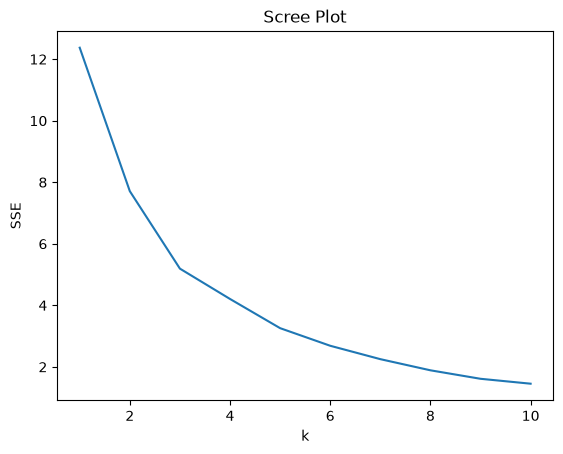

In [ ]:
#determining k* for kmeans cluster for all 4 variables
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Y = (unscaled - mins) / ranges
Y.agg(["min", "max"])

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(Y).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

In [ ]:
#From the scree plot, I am going to use k=5 as my k*

#k-means clustering

features = ["Spending (2020 USD)", "Spending per Capita", 'Percent of Government Spending', "Percent of GDP"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Y = (unscaled - mins) / ranges
Y.agg(["min", "max"])

model = KMeans(n_clusters=5, n_init="auto", random_state=0).fit(Y)
military_copy["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()

military_copy.groupby("cluster").describe()


index                                                            \
        count         mean          std     min     25%     50%     75%   
cluster                                                                   
0        29.0  3021.655172  1635.435116   236.0  1834.0  3024.0  4316.0   
1         2.0  4265.000000   312.541197  4044.0  4154.5  4265.0  4375.5   
2         4.0  3925.000000  1408.574220  2582.0  2837.0  3789.0  4877.0   
3        85.0  2809.600000  1612.992185    32.0  1528.0  2786.0  4180.0   
4        28.0  2441.142857  1811.082134   100.0   729.0  2497.0  3712.5   

                 Year                                                       \
            max count    mean  std     min     25%     50%     75%     max   
cluster                                                                      
0        5574.0  29.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        4486.0   2.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2        5540.0   4.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        5880.0  85.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
4        5438.0  28.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      29.0   15763.285633   18967.087648   405.790494   
1                       2.0   35327.054356   41339.365456  6095.708713   
2                       4.0  204283.345885  382796.365368  6941.042345   
3                      85.0    4553.802712   28003.943870     8.622460   
4                      28.0    7669.951749   17369.175795   163.926877   

                                                                   \
                  25%           50%            75%            max   
cluster                                                             
0         3034.587930   6271.285838   23281.319911   60675.039625   
1        20711.381534  35327.054356   49942.727178   64558.400000   
2         9219.189158  15897.570598  210961.727326  778397.200000   
3           80.370010    287.864078    1144.420381  257973.429834   
4          483.407665   1281.079801    5718.080448   72937.064048   

        Percent of GDP                                                    \
                 count      mean       std       min       25%       50%   
cluster                                                                    
0                 29.0  0.017227  0.005696  0.006273  0.013862  0.018801   
1                  2.0  0.095341  0.004426  0.092211  0.093776  0.095341   
2                  4.0  0.046280  0.016007  0.029429  0.035241  0.045366   
3                 85.0  0.012372  0.005744  0.000054  0.007653  0.012481   
4                 28.0  0.034877  0.011042  0.011742  0.028732  0.032461   

                            Percent of Government Spending            \
              75%       max                          count      mean   
cluster                                                                
0        0.021276  0.028132                           29.0  0.039131   
1        0.096905  0.098470                            2.0  0.202852   
2        0.056405  0.064961                            4.0  0.101600   
3        0.016691  0.026340                           85.0  0.042976   
4        0.040760  0.066600                           28.0  0.125128   

                                                                     \
              std       min       25%       50%       75%       max   
cluster                                                               
0        0.021803  0.011613  0.026080  0.033620  0.046211  0.110270   
1        0.031393  0.180654  0.191753  0.202852  0.213951  0.225050   
2        0.015130  0.081976  0.093906  0.104186  0.111880  0.116052   
3        0.021540  0.004

Similar to the earlier two k MC, the clusters sizes have 2-3 clusters that contain a majority of the points and 1-2 that only hold between 1-5 points. The largest cluster went from 111 to 95 to 85, going from k=4 to k=6 to k=5. Additionally, there is no longer a cluster with 1 point, the US. Means and standard deviationd shifted.

#Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

The clusters allowed me to notice patterns in countries' spending habits, helping me see tiers in military spending intensity: low spenders, medium spenders, and high spenders. The larger clusters identify the "normal" countries, i.e. the countries that spend moderate amounts on their military in terms of dollar amount and percentages of GDP and government spending. Additionally, the clusters with 1-5 points helped me identify outliers in the spending habits, like the US or countries that have a high percent of GDP because they are smaller but spend a lot.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 315e4da
- **AI tool and model used:** ChatGPT (GPT-6)

### *Prompts used

1. make this more efficient with a for loop:
#Making the Scatter plots
fig, axes = plt.subplots(3, 2, figsize=(8, 10))   

sns.scatterplot(
    data=df0_125,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[0,0]
)
sns.scatterplot(
    data=df0_25,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[0,1]
)
sns.scatterplot(
    data=df0_5,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[1,0],
)
sns.scatterplot(
    data=df1_0,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[1,1]
)
sns.scatterplot(
    data=df2_0,
    x="x1",
    y="x2",
    hue="group",
    ax=axes[2,0]
)
plt.tight_layout()
plt.show()

2. make this more efficient with a for loop:
#Scree Plot
from sklearn.cluster import KMeans

fig, axes = plt.subplots(3, 2, figsize=(8,8))


features= ["x1","x2"]

X = df0_125.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[0,0]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X1 = df0_25.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X1).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[0,1]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X2 = df0_5.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X2).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[1,0]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X3 = df1_0.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[1,1]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

X4 = df2_0.loc[:,features]

ks = np.arange(1,11)
SSE = (
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
)
sns.lineplot(x=ks, y=SSE, ax=axes[2,0]).set(title="Scree Plot", xlabel="k", ylabel="SSE")

plt.tight_layout()
plt.show()

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. You can store the DataFrames in a list and loop through them alongside the axes using enumerate():
# Making the scatter plots
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

dfs = [df0_125, df0_25, df0_5, df1_0, df2_0]

for i, df in enumerate(dfs):
    sns.scatterplot(
        data=df,
        x="x1",
        y="x2",
        hue="group",
        ax=axes[i // 2, i % 2]
    )

plt.tight_layout()
plt.show()
How the loop works
- enumerate(dfs) gives you the index i and each DataFrame df.
- i // 2 determines the row of the subplot.
- i % 2 determines the column of the subplot.
- Since you have five DataFrames and six subplot spaces, axes[2, 1] will remain empty.
Optional: To remove the empty sixth subplot, add this before plt.tight_layout():
fig.delaxes(axes[2, 1])
This keeps your code concise while preserving the original plot layout.

2. "You can make this much more efficient by storing your DataFrames and subplot positions in a list, then looping through them to calculate SSE and create each scree plot.
# Scree Plot
from sklearn.cluster import KMeans

fig, axes = plt.subplots(3, 2, figsize=(8, 8))

features = ["x1", "x2"]
ks = np.arange(1, 11)

dfs = [df0_125, df0_25, df0_5, df1_0, df2_0]
titles = ["0.125", "0.25", "0.5", "1.0", "2.0"]

for df, ax, title in zip(dfs, axes.flat, titles):
    X = df.loc[:, features]

    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

    sns.lineplot(x=ks, y=SSE, ax=ax)
    ax.set(title=f"Scree Plot ({title})", xlabel="k", ylabel="SSE")

# Remove the unused sixth subplot
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()
What makes this more efficient?
- dfs stores all five DataFrames, so you don't have to redefine X, X1, X2, etc.
- zip(dfs, axes.flat, titles) lets you iterate through each DataFrame, subplot, and title simultaneously.
- The list comprehension calculates SSE for each \(k=1,\ldots,10\) and stores the results in a list.
- fig.delaxes() removes the unused sixth subplot since you only have five datasets.
One important detail: I changed SSE from a generator expression to a list comprehension ([...]). This ensures all ten SSE values are calculated before they are passed to Seaborn.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | The Gen AI recommended a much shorter code. I checked its work by researching how the enumerate() function works and then running it to make sure there were no errors. |
| 2 | **Accept** / modify / reject | Similar to my first prompt, the AI recommended a much shorter, more efficient code. I checked its output my reading over the loop line by line, researching the flat() method, and then running the code to make sure there were no errors  |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

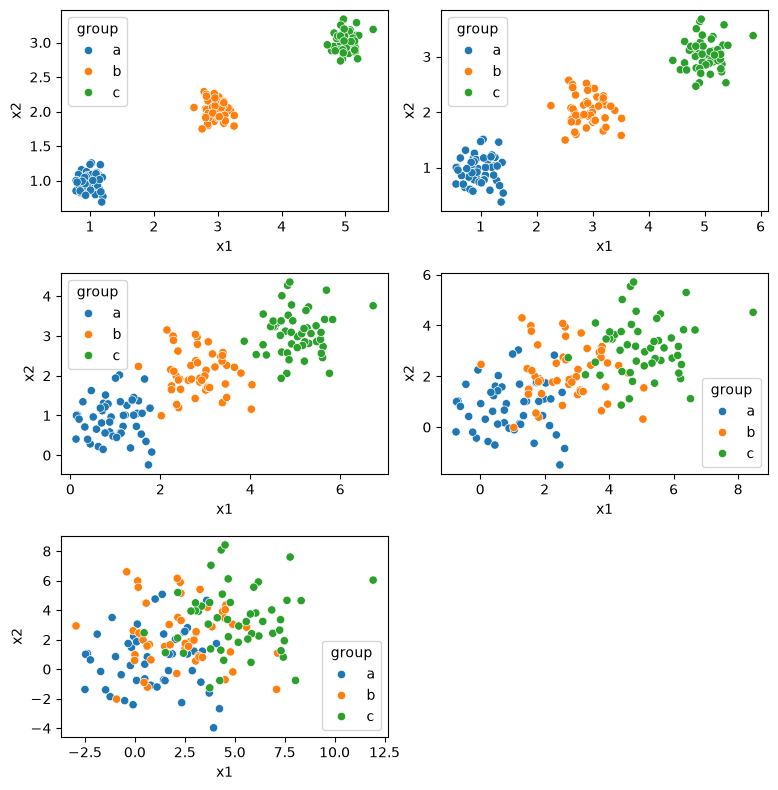

In [ ]:
# Your Phase 2 solution to the problem goes here.
# Making the scatter plots
fig, axes = plt.subplots(3, 2, figsize=(8, 8))

dfs = [df0_125, df0_25, df0_5, df1_0, df2_0]

for i, df in enumerate(dfs):
    sns.scatterplot(
        data=df,
        x="x1",
        y="x2",
        hue="group",
        ax=axes[i // 2, i % 2]
    )

fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

As the noise increases from 0.125 to 2.0, the clusters become less defined, spread aapart, and overlap with the other clusters.

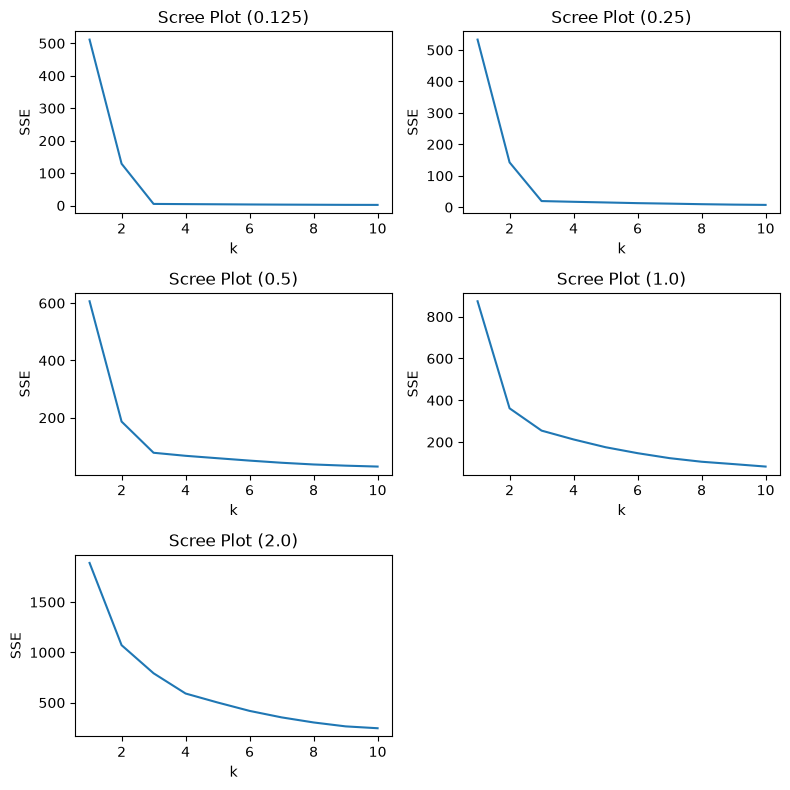

In [ ]:
# Scree Plot
from sklearn.cluster import KMeans

fig, axes = plt.subplots(3, 2, figsize=(8, 8))

features = ["x1", "x2"]
ks = np.arange(1, 11)

dfs = [df0_125, df0_25, df0_5, df1_0, df2_0]
titles = ["0.125", "0.25", "0.5", "1.0", "2.0"]

for i, df in enumerate(dfs):
    X = df.loc[:, features]

    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

    ax = axes.flat[i]
    sns.lineplot(x=ks, y=SSE, ax=ax)
    ax.set(title=f"Scree Plot ({titles[i]})", xlabel="k", ylabel="SSE")

fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

As the datasets' noise increases, their respective Scree Plots smoothen out -- that is to say the defined elbow kink becomes less defined/sharp and a clear elbow becomes harder to see. This makes finding the ideal k much harder because the smoother plots have multiple points where it kinks that defines the curve.

#Explain the intuition of the elbow

The scree plot evaluates the SSE of the clusters evaluated at different values of k. It is often characterized by a noticeable kink in its curve, known as the elbow. An obvious elbow in the scree plot, like in df0_125, tells us what the optimal k value is (ie what the optimal number of clusters in). It tells us the optimal k because before the kink, k is allowing the SSE to have meaningful margins (decreasing by a lot rapidly). However after the kink, the SSE is decreasing at a less meaningful rate like diminishing marginal returns. Thus, adding more ks does not notably minimize our SSE by much more.

When the elbow is clear, we are able to find k* easily. However, when data is noisy, like in our example above with data set df2_0, the scree plot is more curved and visually "kinks" at many different points, making it harder to pinpoint the optimal k.

In [ ]:
military.head()

#copying dataset, dropping NaN values, and filtering it to only Year 2020
military_copy = military.copy().dropna()

military_copy = military_copy.query(
    'Year == 2020'
)

military_copy.head(145) #to see the US data and cross check with cluster data

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5336,5336,2020,Turkey,17478.413685,0.024322,0.071553,207.239992
5404,5404,2020,Uganda,984.759732,0.025971,0.121301,21.529038
5438,5438,2020,Ukraine,5924.200880,0.038118,0.082884,135.459845
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388


[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

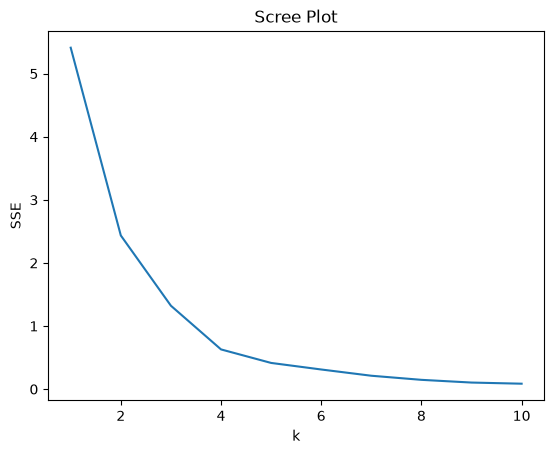

In [ ]:
#max-min normalizign spending 2020 and spending per capita

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Y = (unscaled - mins) / ranges
Y.agg(["min", "max"])

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(Y).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

<Axes: xlabel='Spending (2020 USD)', ylabel='Spending per Capita'>

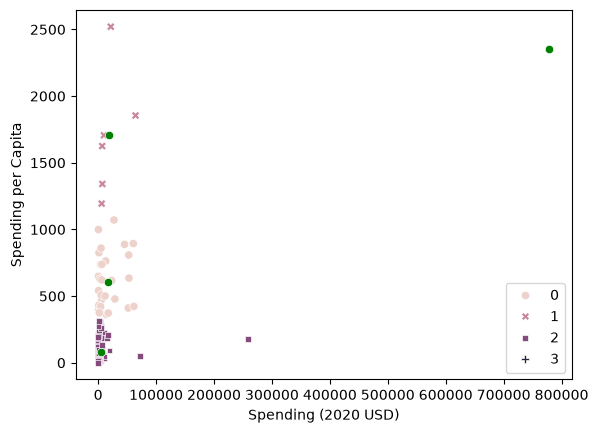

In [ ]:
#Scatter plot of Spending 2020 and Spending per Capita

model = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(Y)
military_copy["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=military_copy, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)

In [ ]:
military_copy.groupby("cluster").describe()

index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
1          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   
2        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
3          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year                                                       \
            max  count    mean  std     min     25%     50%     75%     max   
cluster                                                                       
0        5506.0   30.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        4656.0    6.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2        5880.0  111.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        5540.0    1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Percent of GDP                                                    \
                 count      mean       std       min       25%       50%   
cluster                                                                    
0                 30.0  0.019397  0.009272  0.006273  0.013892  0.018834   
1                  6.0  0.059781  0.031979  0.020060  0.035460  0.059257   
2                111.0  0.017349  0.011699  0.000054  0.010087  0.014389   
3                  1.0  0.037179       NaN  0.037179  0.037179  0.037179   

                            Percent of Government Spending            \
              75%       max                          count      mean   
cluster                                                                
0        0.022515  0.042634                           30.0  0.045588   
1        0.085398  0.098470                            6.0  0.127556   
2        0.021697  0.066600                          111.0  0.062059   
3        0.037179  0.037179                            1.0  0.081976   

                                                                     \
              std       min       25%       50%       75%       max   
cluster                                                               
0        0.030309  0.011613  0.026220  0.036053  0.048819  0.114776   
1        0.066569  0.035207  0.101034  0.113271  0.164503  0.225050   
2        0.045809  0.004896  0.032496  0.048698  0.083508  0.303027   
3             NaN  0.081976  0.081976  0.081976  0.081976  0.081976   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                

#What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

I noticed a few things from the scatterplot and describe table. The United States is the oly data point that makes up cluster 3 becuase its Spending (2020 USD) value is astronomically larger than any of the other countries. This is why there is no standard deviation becuase it is only one point. Cluster 3's central point covers the US's point on the scatterplot and it is visibly on the opposite end of the graph in relation to all of the other points/clusters.

Additionally, the other clusters are located in around 2020 Spending values close to 0. Cluster 2 holds most of the points because they consist of the countries that didn't spend that much in 2020 and had a low spending per capita. Cluster 0 and 1 are the upper two clusters of what appear as a vertically oriented group of points near the y axis. The cluster membership patterns makes sense intuitively as countries that spend less in 2020 means their spending per capita was also low. As the 2020 spending increased, so did the spending per capita, but the number of countries in these clusters decreased.

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

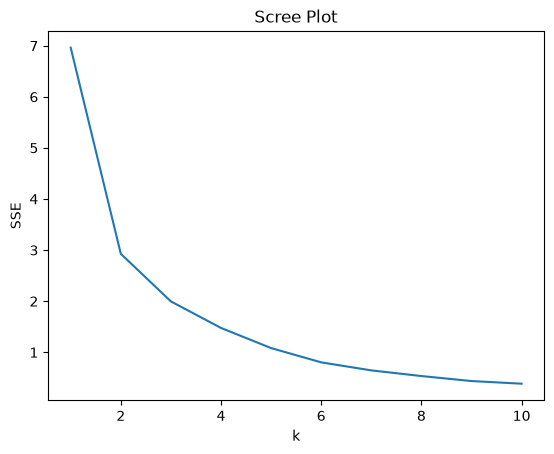

In [ ]:
#max-min normalizing % of government spending and percent of gdp

features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Z = (unscaled - mins) / ranges
Z.agg(["min", "max"])

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(Z).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

<Axes: xlabel='Percent of Government Spending', ylabel='Percent of GDP'>

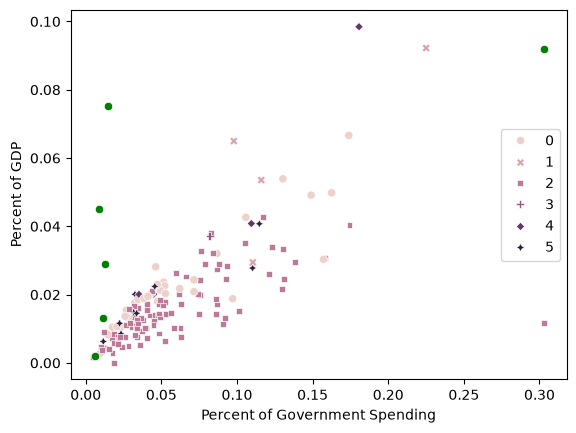

In [ ]:
#Scatter plot of Percent of Government Spending and Percent of GDP

model = KMeans(n_clusters=6, n_init="auto", random_state=0).fit(Y)
military_copy["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=military_copy, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)

In [ ]:
military_copy.groupby("cluster").describe()

index                                                            \
        count         mean          std     min     25%     50%     75%   
cluster                                                                   
0        31.0  2631.354839  1748.447341   100.0  1154.0  2616.0  4350.0   
1         4.0  3661.500000  1061.604289  2582.0  2837.0  3704.0  4528.5   
2        95.0  2849.705263  1626.105986    32.0  1545.0  2956.0  4112.0   
3         1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   
4         4.0  2242.000000  2069.070645   236.0   567.5  2344.0  4018.5   
5        13.0  2890.615385  1658.376593   338.0  1834.0  2854.0  3840.0   

                 Year                                                       \
            max count    mean  std     min     25%     50%     75%     max   
cluster                                                                      
0        5574.0  31.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        4656.0   4.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2        5880.0  95.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        5540.0   1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   
4        4044.0   4.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
5        5506.0  13.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      31.0   16844.488033  47017.556230     483.415023   
1                       4.0   25823.645885  26608.626022    6941.042345   
2                      95.0    2386.131634   8016.263370       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   
4                       4.0   10275.757917  11735.607400     436.548223   
5                      13.0   21161.400440  23080.230883     405.790494   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          1117.977870    3252.505062   10815.977520  257973.429834   
1          9219.189158   15897.570598   32502.027326   64558.400000   
2            86.622424     322.866526    1139.292075   72937.064048   
3        778397.200000  778397.200000  778397.200000  778397.200000   
4          4680.918590    6682.794371   12277.633697   27300.894701   
5          4087.541320    6389.669862   45523.984708   60675.039625   

        Percent of GDP                                                    \
                 count      mean       std       min       25%       50%   
cluster                                                                    
0                 31.0  0.024100  0.014429  0.002875  0.016526  0.020535   
1                  4.0  0.060038  0.026066  0.029429  0.047522  0.059257   
2                 95.0  0.015533  0.009322  0.000054  0.008873  0.013589   
3                  1.0  0.037179       NaN  0.037179  0.037179  0.037179   
4                  4.0  0.044864  0.037048  0.020060  0.020103  0.030463   
5                 13.0  0.017232  0.009017  0.006273  0.013862  0.014517   

                            Percent of Government Spending            \
              75%       max                          count      mean   
cluster                                                                
0        0.026227  0.066600                           31.0  0.063595   
1        0.071773  0.092211                            4.0  0.137368   
2        0.019947  0.042810                           95.0  0.058925   
3        0.037179  0.037179                            1.0  0.081976   
4        0.055224  0.098470                            4.0  0.092578   
5        0.020095  0.040744                         

In comparison to k MC of Spending 2020 and Spending per Capita variables, the points within the Percent of Government Spending and Percent of GDP clusters are more fanned out. The different clusters together appear to create a positive linear shape. Similar to the Sending 2020 and SPending per Capita clusters, many data points in the Government and GDP clusters are consolidated into 2 to 3 of the clusters with 2 clusters only having 1-5 points in them. The US is still within the cluster with only one point, but it is among the other points. There is one point that is far from the other points, but it is part of Cluster 2 which is the largest cluster of them all.

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

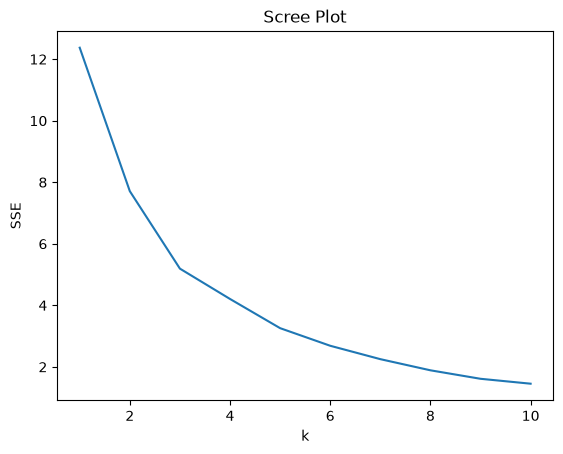

In [ ]:
#determining k* for kmeans cluster for all 4 variables
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Y = (unscaled - mins) / ranges
Y.agg(["min", "max"])

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(Y).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

In [ ]:
#From the scree plot, I am going to use k=5 as my k*

#k-means clustering

features = ["Spending (2020 USD)", "Spending per Capita", 'Percent of Government Spending', "Percent of GDP"]
unscaled = military_copy.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
Y = (unscaled - mins) / ranges
Y.agg(["min", "max"])

model = KMeans(n_clusters=5, n_init="auto", random_state=0).fit(Y)
military_copy["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()

military_copy.groupby("cluster").describe()


index                                                            \
        count         mean          std     min     25%     50%     75%   
cluster                                                                   
0        29.0  3021.655172  1635.435116   236.0  1834.0  3024.0  4316.0   
1         2.0  4265.000000   312.541197  4044.0  4154.5  4265.0  4375.5   
2         4.0  3925.000000  1408.574220  2582.0  2837.0  3789.0  4877.0   
3        85.0  2809.600000  1612.992185    32.0  1528.0  2786.0  4180.0   
4        28.0  2441.142857  1811.082134   100.0   729.0  2497.0  3712.5   

                 Year                                                       \
            max count    mean  std     min     25%     50%     75%     max   
cluster                                                                      
0        5574.0  29.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        4486.0   2.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2        5540.0   4.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        5880.0  85.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
4        5438.0  28.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      29.0   15763.285633   18967.087648   405.790494   
1                       2.0   35327.054356   41339.365456  6095.708713   
2                       4.0  204283.345885  382796.365368  6941.042345   
3                      85.0    4553.802712   28003.943870     8.622460   
4                      28.0    7669.951749   17369.175795   163.926877   

                                                                   \
                  25%           50%            75%            max   
cluster                                                             
0         3034.587930   6271.285838   23281.319911   60675.039625   
1        20711.381534  35327.054356   49942.727178   64558.400000   
2         9219.189158  15897.570598  210961.727326  778397.200000   
3           80.370010    287.864078    1144.420381  257973.429834   
4          483.407665   1281.079801    5718.080448   72937.064048   

        Percent of GDP                                                    \
                 count      mean       std       min       25%       50%   
cluster                                                                    
0                 29.0  0.017227  0.005696  0.006273  0.013862  0.018801   
1                  2.0  0.095341  0.004426  0.092211  0.093776  0.095341   
2                  4.0  0.046280  0.016007  0.029429  0.035241  0.045366   
3                 85.0  0.012372  0.005744  0.000054  0.007653  0.012481   
4                 28.0  0.034877  0.011042  0.011742  0.028732  0.032461   

                            Percent of Government Spending            \
              75%       max                          count      mean   
cluster                                                                
0        0.021276  0.028132                           29.0  0.039131   
1        0.096905  0.098470                            2.0  0.202852   
2        0.056405  0.064961                            4.0  0.101600   
3        0.016691  0.026340                           85.0  0.042976   
4        0.040760  0.066600                           28.0  0.125128   

                                                                     \
              std       min       25%       50%       75%       max   
cluster                                                               
0        0.021803  0.011613  0.026080  0.033620  0.046211  0.110270   
1        0.031393  0.180654  0.191753  0.202852  0.213951  0.225050   
2        0.015130  0.081976  0.093906  0.104186  0.111880  0.116052   
3        0.021540  0.004

Similar to the earlier two k MC, the clusters sizes have 2-3 clusters that contain a majority of the points and 1-2 that only hold between 1-5 points. The largest cluster went from 111 to 95 to 85, going from k=4 to k=6 to k=5. Additionally, there is no longer a cluster with 1 point, the US. Means and standard deviationd shifted.

#Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

The clusters allowed me to notice patterns in countries' spending habits, helping me see tiers in military spending intensity: low spenders, medium spenders, and high spenders. The larger clusters identify the "normal" countries, i.e. the countries that spend moderate amounts on their military in terms of dollar amount and percentages of GDP and government spending. Additionally, the clusters with 1-5 points helped me identify outliers in the spending habits, like the US or countries that have a high percent of GDP because they are smaller but spend a lot.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

When I was originally writing my code, I had attempted to write with a for loop but could not figure out how to iterate over the different axes' rows and columns. By having the help of AI, I was able to shorten my code my a lot so I didn't have to repeat the same steps over and over again to plot each scatterplot and scree plot for Question 1. Additionally, the AI recommendation allowed me to learn two new pandas functions and methods, enumerate() and flat(). These both will be helpful in the future when I need to print several subplots over multiple times.

To verify the code, I first read over it to see if I understood what it was writing. I researched any code I was confused about to make sure it made sense in the context of this problem. Then, I ran the AI generated code within my notebook alongside my own code to see if any errors were produced. When none showed up, I compared the outputs, in this case the graphs, to the ones I got in Phase 1 to make sure they produced the same thing. I did not want the AI to change my outputs, but rather solely make my code more efficient using loops that I knew would help.